# Replicate comparison — rep1 vs rep2 (sc-NOMe-HiC mouse cortex)

Reproducibility of the two biological replicates across **methylation (HCG)**, **accessibility (GCH)**, and **Hi-C**, plus the **methylation–accessibility correlation** within each replicate.

| Replicate | Prefix | Cells |
|---|---|---|
| **rep1** | `scNH_c57cortex_*` | 702 |
| **rep2** | `batch2_*` | 875 |

This notebook **re-computes** the methylation/accessibility comparison directly from the Step-1 pseudobulk tables (fast), and **loads** the Hi-C SCC (Step 3) and decay (Step 5) results produced by the SLURM jobs. Run it top-to-bottom; Hi-C sections show a note if the `.hic` jobs haven't finished yet.

Kernel: `scnomehic` conda env (pandas, numpy, scipy, matplotlib; hicrep/cooler for optional recompute).

In [1]:
import os
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
%matplotlib inline

RC = "/gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic/snakemake/replicate_comparison"
PB_DIR = os.path.join(RC, "pseudobulk")
RES_DIR = os.path.join(RC, "results")
LABEL = "250kb"

REPS = ["rep1", "rep2"]
CTXS = ["GCH", "HCG"]
CTX_NAME = {"GCH": "accessibility (GCH)", "HCG": "methylation (HCG)"}
REP_COL = {"rep1": "#1f77b4", "rep2": "#d62728"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("paths set. pseudobulk dir contents:")
print("\n".join(sorted(os.listdir(PB_DIR))))

paths set. pseudobulk dir contents:
rep1.GCH.250kb.pseudobulk.bedGraph
rep1.GCH.250kb.pseudobulk.txt.gz
rep1.GCH.250kb.qnorm.pseudobulk.bedGraph
rep1.GCH.250kb.qnorm.pseudobulk.txt.gz
rep1.HCG.250kb.pseudobulk.bedGraph
rep1.HCG.250kb.pseudobulk.txt.gz
rep2.GCH.250kb.pseudobulk.bedGraph
rep2.GCH.250kb.pseudobulk.txt.gz
rep2.GCH.250kb.qnorm.pseudobulk.bedGraph
rep2.GCH.250kb.qnorm.pseudobulk.txt.gz
rep2.HCG.250kb.pseudobulk.bedGraph
rep2.HCG.250kb.pseudobulk.txt.gz


## Load pseudobulk profiles

Each table is the **pooled ratio** per 250kb bin (sum `methylated_reads` and `total_reads` across a replicate's cells, then divide). We keep bins with `total_reads > 0`.

In [2]:
def load_pb(rep, ctx):
    f = os.path.join(PB_DIR, f"{rep}.{ctx}.{LABEL}.pseudobulk.txt.gz")
    df = pd.read_csv(f, sep="\t")
    df = df[df["total_reads"] > 0].copy()
    return df[["bin_id", "methylation_level"]].rename(columns={"methylation_level": f"{rep}_{ctx}"})

data = {(rep, ctx): load_pb(rep, ctx) for rep in REPS for ctx in CTXS}
for k, v in data.items():
    print(k, "covered bins:", len(v))

('rep1', 'GCH') covered bins: 10643
('rep1', 'HCG') covered bins: 10623
('rep2', 'GCH') covered bins: 10638
('rep2', 'HCG') covered bins: 10617


## C2. Quantile-normalized accessibility (GCH)

rep1 and rep2 differ in the **absolute** GCH level (a global batch offset in GpC-methyltransferase efficiency: rep1 mean ≈ 0.69 vs rep2 ≈ 0.50), which dominates the raw distribution comparison in Section A. **Quantile normalization** forces the two GCH pseudobulk profiles to share one distribution (reference = mean of the per-rank sorted values across replicates), isolating the accessibility **pattern** from magnitude.

The transform is monotonic within each replicate, so **Spearman correlations are unchanged** — a built-in sanity check; only the distributions and Pearson change. HCG methylation is left raw. (Same calculation as the `06_qnorm_accessibility.py` job, which also writes `pseudobulk/{rep}.GCH.250kb.qnorm.pseudobulk.*`.)

GCH bins quantile-normalized (covered in both reps): 10632


,which,pearson_r,spearman_r,ks_rep1_vs_rep2
0,raw,0.8129,0.9691,0.9683
1,qnorm,0.8310,0.9691,0.0003


,rep,n_bins,pearson_r,spearman_r
0,rep1,10616,-0.4145,-0.5899
1,rep2,10616,-0.4461,-0.6258


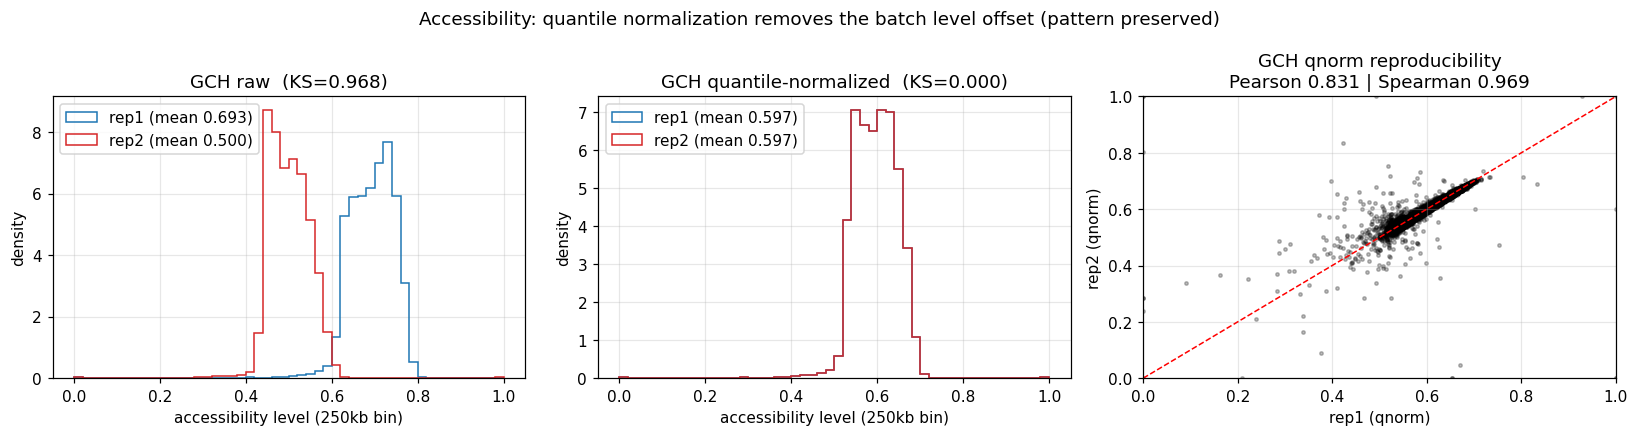

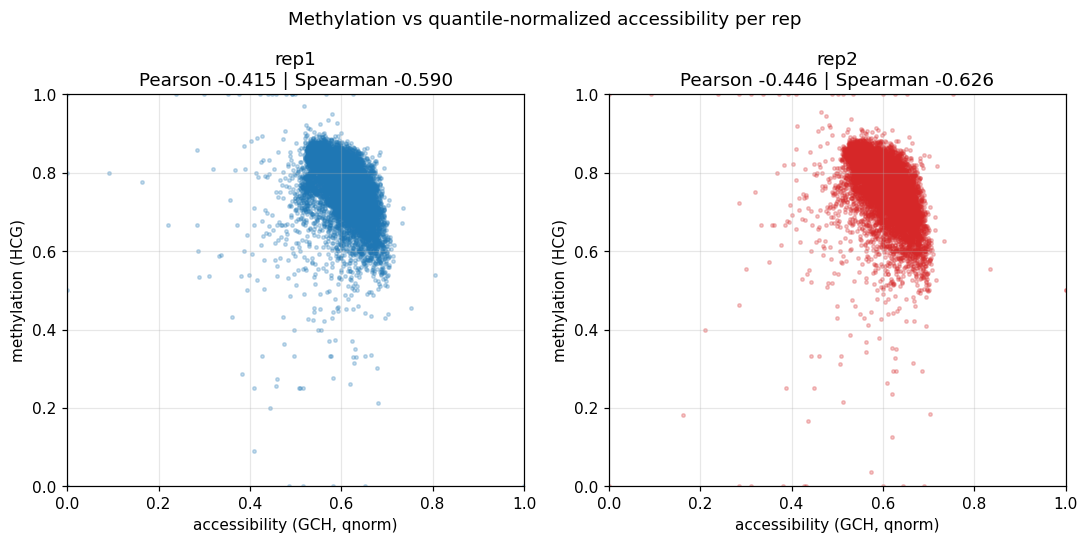

In [6]:
# --- quantile normalization of accessibility (GCH) across the two replicates ---
def quantile_normalize(df):
    """features x samples -> each column forced to a common distribution
    (reference = mean of the per-rank sorted values across samples). Ties use
    average rank + linear interpolation, so the map is monotonic within a
    column: Spearman is preserved, only magnitudes / Pearson change."""
    vals = df.to_numpy(dtype=float)
    n = vals.shape[0]
    reference = np.sort(vals, axis=0).mean(axis=1)       # ascending, length n
    positions = np.arange(1, n + 1)
    out = np.empty_like(vals)
    for j in range(vals.shape[1]):
        ranks = pd.Series(vals[:, j]).rank(method="average").to_numpy()
        out[:, j] = np.interp(ranks, positions, reference)
    return pd.DataFrame(out, index=df.index, columns=df.columns)

# GCH matrix over bins covered in BOTH replicates, then quantile-normalize
gch_mat = (data[("rep1", "GCH")].set_index("bin_id")["rep1_GCH"].to_frame()
           .join(data[("rep2", "GCH")].set_index("bin_id")["rep2_GCH"], how="inner")
           .dropna())
gch_qn = quantile_normalize(gch_mat)
print(f"GCH bins quantile-normalized (covered in both reps): {len(gch_qn)}")

def _rk(x, y):
    return (stats.pearsonr(x, y).statistic, stats.spearmanr(x, y).statistic,
            stats.ks_2samp(x, y).statistic)
pr_r, sp_r, ks_r = _rk(gch_mat["rep1_GCH"].values, gch_mat["rep2_GCH"].values)
pr_q, sp_q, ks_q = _rk(gch_qn["rep1_GCH"].values, gch_qn["rep2_GCH"].values)
repro_qn = pd.DataFrame([
    {"which": "raw",   "pearson_r": pr_r, "spearman_r": sp_r, "ks_rep1_vs_rep2": ks_r},
    {"which": "qnorm", "pearson_r": pr_q, "spearman_r": sp_q, "ks_rep1_vs_rep2": ks_q},
])
display(repro_qn.round(4))

# methylation vs QN'd accessibility, per replicate (HCG stays raw)
ma_qn_rows, ma_qn_merged = [], {}
for rep in REPS:
    hcg = data[(rep, "HCG")].set_index("bin_id")[f"{rep}_HCG"]
    m = pd.DataFrame({"GCH_qn": gch_qn[f"{rep}_GCH"], "HCG": hcg}).dropna()
    ma_qn_rows.append({"rep": rep, "n_bins": len(m),
                       "pearson_r": stats.pearsonr(m["GCH_qn"], m["HCG"]).statistic,
                       "spearman_r": stats.spearmanr(m["GCH_qn"], m["HCG"]).statistic})
    ma_qn_merged[rep] = m
ma_qn = pd.DataFrame(ma_qn_rows)
display(ma_qn.round(4))

# --- distributions before/after + reproducibility scatter ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for rep in REPS:
    axes[0].hist(gch_mat[f"{rep}_GCH"], bins=50, range=(0, 1), histtype="step", density=True,
                 color=REP_COL[rep], lw=1.8, label=f"{rep} (mean {gch_mat[f'{rep}_GCH'].mean():.3f})")
    axes[1].hist(gch_qn[f"{rep}_GCH"], bins=50, range=(0, 1), histtype="step", density=True,
                 color=REP_COL[rep], lw=1.8, label=f"{rep} (mean {gch_qn[f'{rep}_GCH'].mean():.3f})")
axes[0].set_title(f"GCH raw  (KS={ks_r:.3f})")
axes[1].set_title(f"GCH quantile-normalized  (KS={ks_q:.3f})")
for ax in axes[:2]:
    ax.set_xlabel("accessibility level (250kb bin)"); ax.set_ylabel("density"); ax.legend()
axes[2].scatter(gch_qn["rep1_GCH"], gch_qn["rep2_GCH"], s=5, alpha=0.25, color="k")
axes[2].plot([0, 1], [0, 1], "r--", lw=1)
axes[2].set_title(f"GCH qnorm reproducibility\nPearson {pr_q:.3f} | Spearman {sp_q:.3f}")
axes[2].set_xlabel("rep1 (qnorm)"); axes[2].set_ylabel("rep2 (qnorm)")
axes[2].set_xlim(0, 1); axes[2].set_ylim(0, 1)
fig.suptitle("Accessibility: quantile normalization removes the batch level offset (pattern preserved)")
fig.tight_layout(); plt.show()

# --- methylation vs QN'd accessibility ---
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, rep in zip(axes, REPS):
    m = ma_qn_merged[rep]
    ax.scatter(m["GCH_qn"], m["HCG"], s=5, alpha=0.25, color=REP_COL[rep])
    r = ma_qn.loc[ma_qn.rep == rep].iloc[0]
    ax.set_title(f"{rep}\nPearson {r.pearson_r:.3f} | Spearman {r.spearman_r:.3f}")
    ax.set_xlabel("accessibility (GCH, qnorm)"); ax.set_ylabel("methylation (HCG)")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
fig.suptitle("Methylation vs quantile-normalized accessibility per rep")
fig.tight_layout(); plt.show()

# Publication figures

Standalone, publication-styled scatter plots (density-colored, editable-text PDF + 300-dpi PNG, saved to `results/figures_pub/`):

1. **HCG methylation reproducibility** — rep1 vs rep2 per 250kb bin.
2. **GCH accessibility reproducibility** — rep1 vs rep2, **quantile-normalized**.
3. **Methylation ↔ accessibility correlation** — HCG vs GCH(qnorm), one figure per replicate.

Each panel annotates Pearson *r*, Spearman *ρ*, and *n* bins. Requires Section C2 (defines `gch_qn`, `ma_qn_merged`) to have run.

In [7]:
# --- publication style + density-scatter helpers ---
FIG_DIR = os.path.join(RES_DIR, "figures_pub")
os.makedirs(FIG_DIR, exist_ok=True)

PUB = {
    "figure.dpi": 130, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.family": "DejaVu Sans", "font.size": 13,
    "axes.labelsize": 14, "axes.titlesize": 14, "axes.linewidth": 1.1,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.direction": "out", "ytick.direction": "out",
    "xtick.major.size": 4, "ytick.major.size": 4, "axes.grid": False,
    "legend.frameon": False, "pdf.fonttype": 42, "ps.fonttype": 42,
}

def density_scatter(ax, x, y, bins=60, cmap="viridis", s=10):
    """Scatter with points colored by local 2D-histogram density (dense on top)."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    H, xe, ye = np.histogram2d(x, y, bins=bins, range=[[0, 1], [0, 1]])
    ix = np.clip(np.searchsorted(xe, x, "right") - 1, 0, bins - 1)
    iy = np.clip(np.searchsorted(ye, y, "right") - 1, 0, bins - 1)
    z = H[ix, iy]
    o = z.argsort()
    return ax.scatter(x[o], y[o], c=z[o], s=s, cmap=cmap, edgecolor="none", rasterized=True)

def annot_corr(ax, x, y, extra=""):
    r = stats.pearsonr(x, y).statistic
    rho = stats.spearmanr(x, y).statistic
    ax.text(0.04, 0.96, f"$r$ = {r:.3f}\n$\\rho$ = {rho:.3f}\n$n$ = {len(x):,}{extra}",
            transform=ax.transAxes, va="top", ha="left", fontsize=12,
            bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.7", alpha=0.9))
    return r, rho

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + ".pdf"))
    fig.savefig(os.path.join(FIG_DIR, name + ".png"))
    print("saved", os.path.join(FIG_DIR, name + ".{pdf,png}"))

print("publication figure dir:", FIG_DIR)

publication figure dir: /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic/snakemake/replicate_comparison/results/figures_pub


### Figure 4b — same, in the plain Section-B scatter style (larger text)

Identical data to Figure 4 (GCH quantile-normalized, HCG methylation raw), but drawn in the simple Section-B style — plain black points + red dashed identity line, with `Pearson | Spearman` in each title — and enlarged fonts. Saved to `results/figures_pub/repro_GCH_HCG_qnorm_plain.*`.

,context,n_bins,pearson_r,spearman_r
0,GCH,10632,0.8310,0.9691
1,HCG,10612,0.9202,0.9776


saved /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic/snakemake/replicate_comparison/results/figures_pub/repro_GCH_HCG_qnorm_plain.{pdf,png}


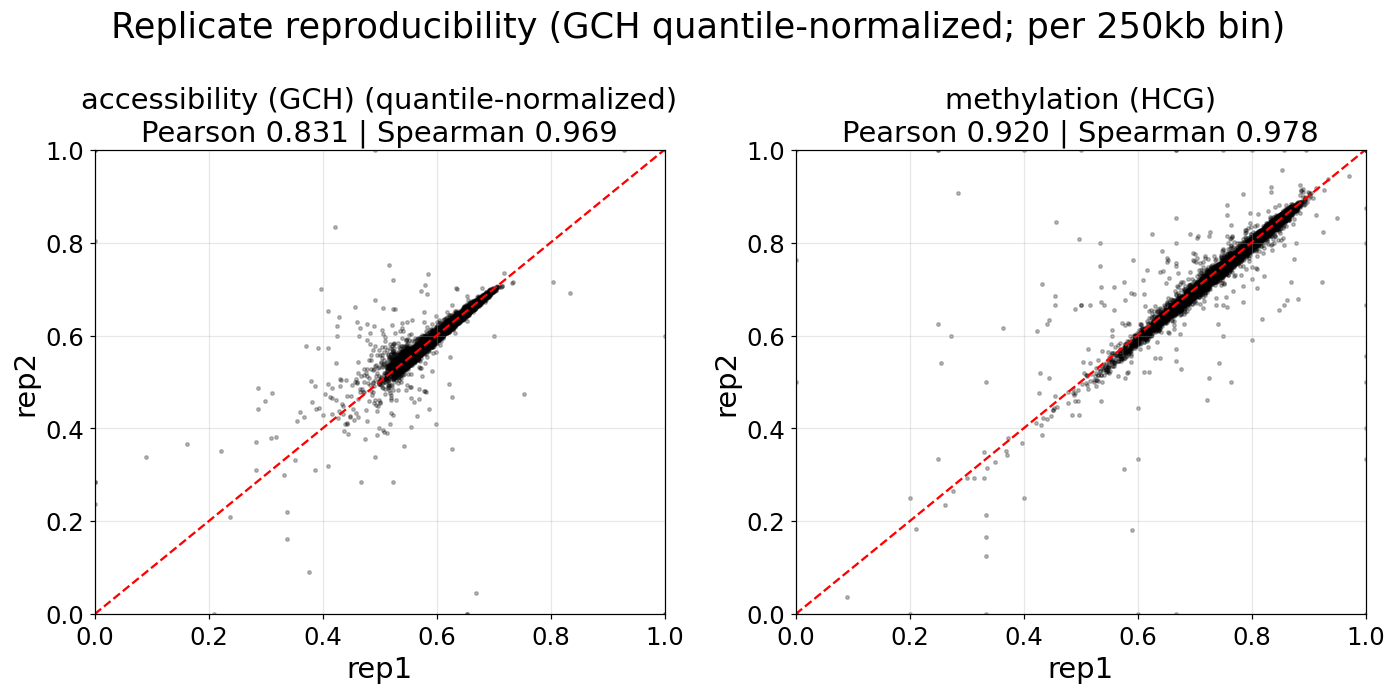

In [12]:
# Figure 4b — reproducibility (Section-B plain style), GCH quantile-normalized, HCG raw, larger text
repro_rows2, repro_merged2 = [], {}
NORM_LBL = {"GCH": " (quantile-normalized)", "HCG": ""}   # HCG methylation left raw
for ctx in CTXS:
    mat = (data[("rep1", ctx)].set_index("bin_id")[f"rep1_{ctx}"].to_frame()
           .join(data[("rep2", ctx)].set_index("bin_id")[f"rep2_{ctx}"], how="inner")
           .dropna())
    if ctx == "GCH":
        mat = quantile_normalize(mat)   # only accessibility is quantile-normalized
    x, y = mat[f"rep1_{ctx}"].values, mat[f"rep2_{ctx}"].values
    pr, sr = stats.pearsonr(x, y), stats.spearmanr(x, y)
    repro_rows2.append({"context": ctx, "n_bins": len(mat),
                        "pearson_r": pr.statistic, "spearman_r": sr.statistic})
    repro_merged2[ctx] = mat
repro2 = pd.DataFrame(repro_rows2)
display(repro2.round(4))

with plt.rc_context({"font.size": 17, "axes.titlesize": 19, "axes.labelsize": 19,
                     "xtick.labelsize": 16, "ytick.labelsize": 16, "figure.titlesize": 23}):
    fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
    for ax, ctx in zip(axes, CTXS):
        q = repro_merged2[ctx]
        ax.scatter(q[f"rep1_{ctx}"], q[f"rep2_{ctx}"], s=5, alpha=0.25, color="k")
        ax.plot([0, 1], [0, 1], "r--", lw=1.5)
        r = repro2.loc[repro2.context == ctx].iloc[0]
        ax.set_title(f"{CTX_NAME[ctx]}{NORM_LBL[ctx]}\n"
                     f"Pearson {r.pearson_r:.3f} | Spearman {r.spearman_r:.3f}")
        ax.set_xlabel("rep1"); ax.set_ylabel("rep2"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    fig.suptitle("Replicate reproducibility (GCH quantile-normalized; per 250kb bin)")
    fig.tight_layout()
    save_fig(fig, "repro_GCH_HCG_qnorm_plain")
    plt.show()

### D-pub. SCC violins in the cellline 3b style — two separate figures

The same publication violin format as `hic_comparison_gm_clean.ipynb` §3b (`#aac9e3` bodies, red median, despined, Arial, y 0–1), produced as **two standalone figures**: SCC across resolutions for **raw** and for **95th-pct clip**. All chromosomes kept (no chr4 exclusion — that was GM12878-specific). Saved to `results/figures_pub/scc_violin_raw.*` and `scc_violin_clip95.*`.

rep1 vs rep2 Hi-C SCC (raw):


,median,mean,std,n
1Mb,0.843,0.740,0.236,20.0
500kb,0.896,0.779,0.233,20.0
250kb,0.908,0.856,0.137,20.0


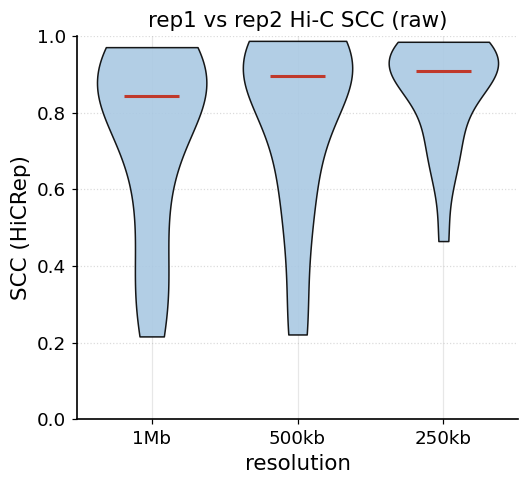

[OK] -> /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic/snakemake/replicate_comparison/results/figures_pub/scc_violin_raw.{pdf,png}
rep1 vs rep2 Hi-C SCC (95th-pct clip):


,median,mean,std,n
1Mb,1.0,0.999,0.004,20.0
500kb,1.0,0.999,0.003,20.0
250kb,1.0,0.997,0.004,20.0


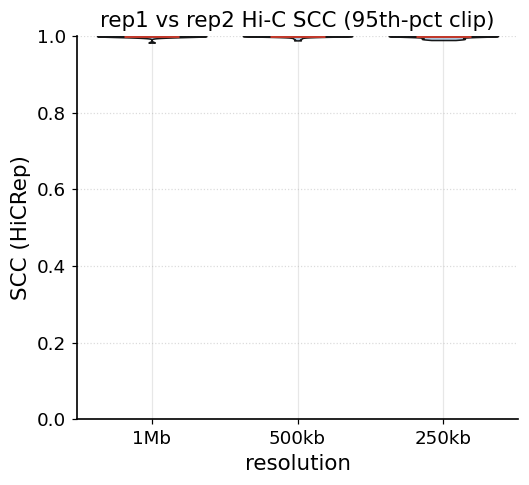

[OK] -> /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic/snakemake/replicate_comparison/results/figures_pub/scc_violin_clip95.{pdf,png}


In [14]:
# SCC violins in the cellline 3b style -- TWO separate figures (raw; 95th-pct clip)
import matplotlib as mpl

scc = pd.read_csv(os.path.join(RES_DIR, "scc", "scc_by_chrom_and_resolution.csv"))
RESLABS = ["1Mb", "500kb", "250kb"]

SCC_STYLE = {"pdf.fonttype": 42, "ps.fonttype": 42, "font.family": "sans-serif",
             "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
             "font.size": 13, "axes.titlesize": 14, "axes.labelsize": 14,
             "xtick.labelsize": 12, "ytick.labelsize": 12, "axes.linewidth": 1.1,
             "savefig.dpi": 300, "savefig.bbox": "tight"}

def scc_violin(col, title, savename):
    data = [scc.loc[scc.resolution == r, col].dropna().values for r in RESLABS]
    summ = pd.DataFrame({r: [np.median(d), np.mean(d), np.std(d), len(d)]
                         for r, d in zip(RESLABS, data)},
                        index=["median", "mean", "std", "n"]).T
    print(f"{title}:")
    display(summ.round(3))
    with mpl.rc_context(SCC_STYLE):
        pos = np.arange(1, len(RESLABS) + 1)
        fig, ax = plt.subplots(figsize=(5.0, 4.6))
        parts = ax.violinplot(data, positions=pos, widths=0.75,
                              showmedians=True, showextrema=False)
        for b in parts["bodies"]:
            b.set_facecolor("#aac9e3"); b.set_edgecolor("black")
            b.set_alpha(0.9); b.set_linewidth(1.0)
        parts["cmedians"].set_color("#c0392b"); parts["cmedians"].set_linewidth(2.0)
        ax.set_xticks(pos); ax.set_xticklabels(RESLABS)
        ax.set_ylim(0, 1.0)
        ax.set_ylabel("SCC (HiCRep)"); ax.set_xlabel("resolution")
        ax.set_title(title)
        ax.spines[["top", "right"]].set_visible(False)
        ax.set_axisbelow(True); ax.yaxis.grid(True, ls=":", alpha=0.45)
        fig.tight_layout()
        fig.savefig(os.path.join(FIG_DIR, savename + ".pdf"))
        fig.savefig(os.path.join(FIG_DIR, savename + ".png"))
        plt.show()
    print("[OK] ->", os.path.join(FIG_DIR, savename + ".{pdf,png}"))

# Figure — raw SCC (primary)
scc_violin("scc_raw", "rep1 vs rep2 Hi-C SCC (raw)", "scc_violin_raw")
# Figure — 95th-percentile clip SCC (cellline 3b formula; saturates on the deep cortex data)
scc_violin("scc_clip95", "rep1 vs rep2 Hi-C SCC (95th-pct clip)", "scc_violin_clip95")

### D-pub2. SCC violins at clip percentiles 95, 96, 97, 98, 99 (cellline 3b style)

One standalone violin figure per clip percentile (95→99), same 3b style. Data from the focused sweep `results/scc_clip95to99/` (`03b_scc_clip_sweep.py --pcts 95,96,97,98,99`). These show the clip staying saturated (~1.0) through 95–98 and only starting to break apart at 99 — confirming there's no usable clip in this window for the deep cortex data. Saved as `results/figures_pub/scc_violin_clip{95..99}.*`.

clip 95th pct  ->  medians 1Mb 1.000, 500kb 1.000, 250kb 1.000


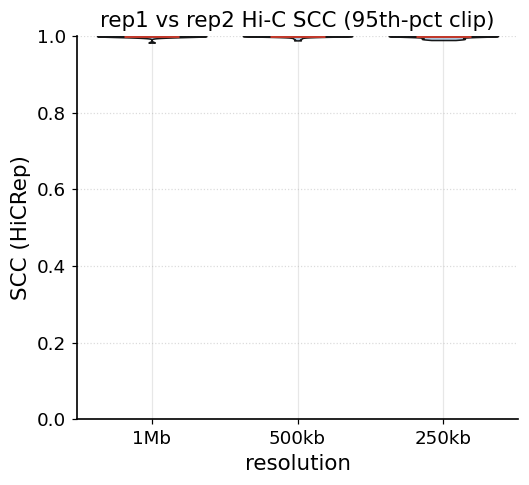

clip 96th pct  ->  medians 1Mb 1.000, 500kb 1.000, 250kb 1.000


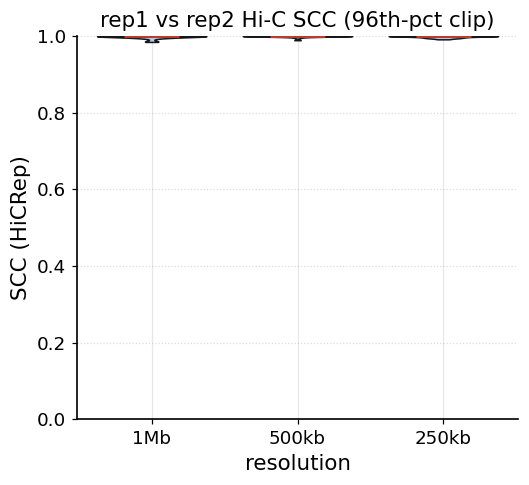

clip 97th pct  ->  medians 1Mb 0.998, 500kb 1.000, 250kb 1.000


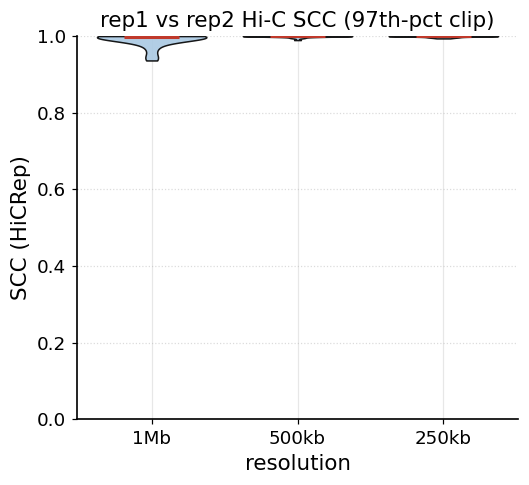

clip 98th pct  ->  medians 1Mb 0.949, 500kb 0.999, 250kb 0.999


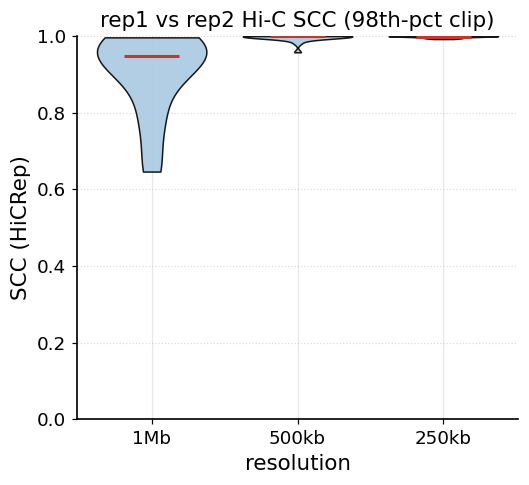

clip 99th pct  ->  medians 1Mb 0.577, 500kb 0.917, 250kb 0.997


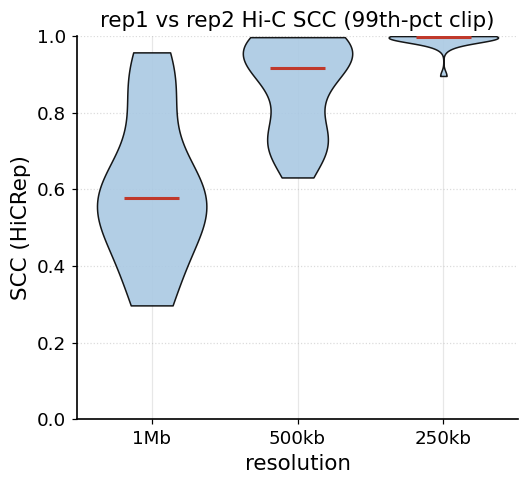

[OK] -> scc_violin_clip95..99 in /gpfs/projects/b1198/epifluidlab/yoshii/sc_nomehic/snakemake/replicate_comparison/results/figures_pub


In [15]:
# SCC violins in the cellline 3b style -- one figure per clip percentile (95,96,97,98,99)
sweep95 = pd.read_csv(os.path.join(RES_DIR, "scc_clip95to99", "scc_clip_sweep.csv"))
RESLABS = ["1Mb", "500kb", "250kb"]

for p in [95, 96, 97, 98, 99]:
    sub = sweep95[sweep95.percentile == p]
    data = [sub.loc[sub.resolution == r, "scc"].dropna().values for r in RESLABS]
    print(f"clip {p}th pct  ->  medians " +
          ", ".join(f"{r} {np.median(d):.3f}" for r, d in zip(RESLABS, data)))
    with mpl.rc_context(SCC_STYLE):
        pos = np.arange(1, len(RESLABS) + 1)
        fig, ax = plt.subplots(figsize=(5.0, 4.6))
        parts = ax.violinplot(data, positions=pos, widths=0.75,
                              showmedians=True, showextrema=False)
        for b in parts["bodies"]:
            b.set_facecolor("#aac9e3"); b.set_edgecolor("black")
            b.set_alpha(0.9); b.set_linewidth(1.0)
        parts["cmedians"].set_color("#c0392b"); parts["cmedians"].set_linewidth(2.0)
        ax.set_xticks(pos); ax.set_xticklabels(RESLABS)
        ax.set_ylim(0, 1.0)
        ax.set_ylabel("SCC (HiCRep)"); ax.set_xlabel("resolution")
        ax.set_title(f"rep1 vs rep2 Hi-C SCC ({p}th-pct clip)")
        ax.spines[["top", "right"]].set_visible(False)
        ax.set_axisbelow(True); ax.yaxis.grid(True, ls=":", alpha=0.45)
        fig.tight_layout()
        fig.savefig(os.path.join(FIG_DIR, f"scc_violin_clip{p}.pdf"))
        fig.savefig(os.path.join(FIG_DIR, f"scc_violin_clip{p}.png"))
        plt.show()
print("[OK] -> scc_violin_clip95..99 in", FIG_DIR)